# Project 2: Numerical Integration For Charged Particles


# 1. Importer

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from time import perf_counter
from tqdm import tqdm
from scipy.optimize import approx_fprime

# 2. Modellproblemer

In [161]:
# Felles modellproblemer (brukes av Boris, RK4 og FOSMM)

# 2D charged particle
# The static magnetic field
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

# The vector potential
def A_2D(x):
    Ax = -x[1]*np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0]*np.sqrt(x[0]**2 + x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])

# The electrostatic potential
def U_2D(x):
    return 1/(100*np.sqrt(x[0]**2 + x[1]**2))

# The gradient of the electrostatic potential
def grad_U_2D(x):
    Ux = x[0]/((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1]/((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100*np.array([Ux, Uy, Uz])

# Initial values
x0_2D = np.array([0.0, 1.0, 0.1])
v0_2D = np.array([0.09, 0.05, 0.20])


# Tokamak magnetic field
# The static magnetic field
def B_tokamak(x):
    Bx = -(2*x[1] + x[0]*x[2])/(2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2])/(2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1)/(2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])

# The vector potential (arctan2, so it is correct also for x[0] < 0)
def A_tokamak(x):
    Ax = 0
    Ay = 1/2*(x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2*(x[2]*np.arctan2(x[1], x[0]) + np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])

# The electrostatic potential
def U_tokamak(x):
    return 0

# The gradient of the electrostatic potential
def grad_U_tokamak(x):
    return 0

# Initial values
x0_tokamak = np.array([1.2, 0.0, 0.0])
v0_tokamak = np.array([0, 4.816e-4, -2.059e-3])

In [162]:
# Felles funksjoner

# Right-hand side of the ODE  x' = v,  v' = v x B(x) - grad U(x)
def ODEs(t, y, B, grad_U):
    x = y[:3]
    v = y[3:]

    dxdt = v
    dvdt = np.cross(v, B(x)) - grad_U(x)
    return np.concatenate((dxdt, dvdt))

# Energy  E = 1/2 |v|^2 + U(x).  x and v are either single vectors or arrays of shape (3, N)
def energy(x, v, U):
    return 0.5*(np.linalg.norm(v, ord=2, axis = 0))**2 + U(x)

# |E(t) - E(0)|, where E(0) is taken from the first column
def energy_change(x, v, U):
    return np.abs(energy(x, v, U) - energy(x[:,0], v[:,0], U))

# 3. Implementering av metodene

# Implementation of Boris method

In [ ]:
def boris_method(ODEs, x0, v0, h, U, U_grad, B, bool_init,N):
    """
    General Boris method
    """
    # If the initial condition is the actual initial condition (want one step back)
    v_back = v0

    if bool_init: #if we are given (x0,v0) instead
        t_0 = 0
        t_back = t_0-(h/2)
        t_span = [t_0, t_back]

        initial_condition = np.concatenate((x0,v0))

        sol = solve_ivp(ODEs, t_span, initial_condition, args=(B, U_grad), first_step = (h/2), rtol=1e-10, atol=1e-12)
        v_back = sol.y[3:,-1] #???????????
    
    # The actual Boris method

    x_n = x0
    v_n_half = v_back
    
    x_array = np.zeros((3,N)) 
    v_array = np.zeros((3,N))

    start = perf_counter() # START MEASURING TIME

    for i in range(0,N):
        t = h/2*B(x_n)
        s = 2*t / (1 + np.dot(t, t))

        v_minus = v_n_half - (h/2)*U_grad(x_n)
        v_mark = v_minus + np.cross(v_minus, t)
        
        v_pluss = v_minus + np.cross(v_mark,s)

        v_n_pluss_half = v_pluss - (h/2)*U_grad(x_n)
        x_n_pluss_one = x_n + h*v_n_pluss_half

        # Update values:
        x_n = x_n_pluss_one
        v_n_half = v_n_pluss_half

        #put values into lists for plotting
        x_array[:,i] = x_n
        v_array[:,i] = v_n_half

    end = perf_counter() # STOP MEASURING TIME

    time_spent = end - start
        
    return x_array, v_array, time_spent

## RK4

### Classical Runge-Kutta 4 on the extended system

In [164]:
#ODEs (the right-hand side) is defined together with the model problems

#Defining the Runge Kutta 4 method

def RK4_step(y_n, h, B, grad_U):
    k_1 = h * ODEs(0, y_n, B, grad_U)
    k_2 = h * ODEs(0, y_n + 0.5*k_1, B, grad_U)
    k_3 = h * ODEs(0, y_n + 0.5*k_2, B, grad_U)
    k_4 = h * ODEs(0, y_n + k_3, B, grad_U)

    return y_n + (k_1 + 2*k_2 + 2*k_3 + k_4)/6

## FOSMM

Implementation of Fourth-order symmetric multistep method:

In [165]:
def starting_values(y0, t_min, t_max, U_grad, B):
    t_vals = np.linspace(t_min, t_max, 8)
    solution = solve_ivp(ODEs,(t_min,t_max) , np.concatenate(y0), args=(B, U_grad), t_eval = t_vals, rtol=1e-12, atol=1e-14, method="DOP853") #y0 must be [x0, v0]
    return solution.y, solution.t

def v(x,j, h):
    return delta(x, j)/h

def delta(y, j):#five point central difference
    return 1/12*(y[:,j-2] - 8*y[:,j-1] + 8*y[:,j+1] - y[:,j+2])

def deltaA(A, x, j):#five point central difference
    return 1/12*(A(x[:,j-2]) - 8*A(x[:,j-1]) + 8*A(x[:,j+1]) - A(x[:,j+2]))

def F_j(A, v, U_grad, j, x, h):
    A_jac = np.transpose(approx_fprime(x[:,j], A))

    A_delta = deltaA(A,x, j)/h
    return A_jac@v(x,j,h) - A_delta - U_grad(x[:,j])

def FOSMM_step(alpha, x , n, h, A, v, U_grad, beta): #find x_(n+4)
    sum = 0
    for j in range(-4, 4):
        sum += alpha[4+j]*x[:,n+j]
    x[:,n+4] = 1/alpha[-1]*(h**2*(beta[1]*F_j(A, v, U_grad,  n-1, x, h) + beta[0]*F_j(A, v, U_grad, n, x, h) + beta[1]*F_j(A, v, U_grad, n+1, x, h))  - sum)

def t_j(t0, j, h):
    return t0 + j*h

def FOSMM(alpha, h, A, U_grad,B, beta, T_max, y0): #y0 = [x0, v0]
    N = int(T_max/h) + 1 #number of steps
    start_vals = starting_values(y0, 0, 7*h, U_grad, B) #0 til 7 riktig??
    x_start = start_vals[0][:3, :] #from t= 0 to 7
    v_start = start_vals[0][3:, :]

    x_arr = np.zeros((3,N+2))
    v_arr = np.zeros((3,N))

    x_arr[:, :8] = x_start    
    v_arr[:, :8] = v_start

    start = perf_counter()
    for n in range(8, N+2): #evaluate two extra steps in order to find the last value of v

        FOSMM_step(alpha, x_arr, n-4, h, A, v, U_grad, beta)
        v_arr[:,n-2] = v(x_arr, n-2, h)

    stop = perf_counter()
    return x_arr[:, :N], v_arr, stop - start


a = [-0.7, 0.1, 0.9]
beta = [1/3*(20*a[0]*a[1]*a[2]-4*(a[0]*a[1]+a[0]*a[2] + a[1]*a[2])-28*(a[0] + a[1] + a[2])-52), 1/3*(2*a[0]*a[1]*a[2] + 14*(a[0]*a[1] + a[0]*a[2] + a[1]*a[2]) + 26*(a[0]+a[1]+a[2]) + 38)]
alpha = [1, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1]

# 4. Task A: Kjøring og baneplott

#### Parameters and initial conditions for task A (shared by all methods)

In [ ]:
# Parameters for task A, shared by Boris, RK4 and FOSMM
T_A = 1e5
h_A = 0.1
N_A = int(T_A/h_A)                    # number of time steps
t_A = np.linspace(0, T_A, N_A + 1)    # t_0 = 0, t_1, ..., t_N = T_A
t_A_boris = t_A[1:]                   # boris_method stores x at t_1, ..., t_N (not x_0)

# Initial conditions as one vector y0 = [x0, v0]
y0_2D = np.concatenate((x0_2D, v0_2D))
y0_tok = np.concatenate((x0_tokamak, v0_tokamak))

# FOSMM takes the initial condition as a 2x3 array [x0, v0]
y0_FOSMM_2D = np.array([x0_2D, v0_2D])
y0_FOSMM_tok = np.array([x0_tokamak, v0_tokamak])

#### INITIALIZING ARRAYS FOR BORIS

In [166]:
# BORIS
x_boris_2D, v_boris_2D, _ = boris_method(ODEs, x0_2D, v0_2D, h_A, U_2D, grad_U_2D, B_2D, True, N_A)

x_boris_tok, v_boris_tok, _ = boris_method(ODEs, x0_tokamak, v0_tokamak, h_A, U_tokamak, grad_U_tokamak, B_tokamak, True, N_A)

R_boris_tok = np.sqrt(x_boris_tok[0]**2 + x_boris_tok[1]**2)
z_boris_tok = x_boris_tok[2]

''

#### INITIALIZING ARRAYS FOR RK4 2D particle

In [167]:
# RK4, 2D particle
y_RK4_2D = np.zeros((N_A + 1, 6))     # row k is [x, v] at t_k
y_RK4_2D[0] = y0_2D

y_n = y0_2D.copy()
for i in tqdm(range(N_A)):
    y_n = RK4_step(y_n, h_A, B_2D, grad_U_2D)
    y_RK4_2D[i+1] = y_n

# Extracting position and velocity
x_RK4_2D = y_RK4_2D[:, :3]
v_RK4_2D = y_RK4_2D[:, 3:]

100%|██████████| 1000000/1000000 [01:28<00:00, 11274.10it/s]


#### INITIALIZING ARRAYS FOR RK4 TOKAMAK MAGNETIC FIELD

In [168]:
# RK4, Tokamak field
y_RK4_tok = np.zeros((N_A + 1, 6))    # row k is [x, v] at t_k
y_RK4_tok[0] = y0_tok

y_n = y0_tok.copy()
for i in tqdm(range(N_A)):
    y_n = RK4_step(y_n, h_A, B_tokamak, grad_U_tokamak)
    y_RK4_tok[i+1] = y_n

# Extracting position and velocity
x_RK4_tok = y_RK4_tok[:, :3]
v_RK4_tok = y_RK4_tok[:, 3:]

100%|██████████| 1000000/1000000 [01:38<00:00, 10183.36it/s]


In [169]:
# Cylindrical coordinates (R, z) for the Tokamak trajectory
R_RK4_tok = np.sqrt(x_RK4_tok[:, 0]**2 + x_RK4_tok[:, 1]**2)
z_RK4_tok = x_RK4_tok[:, 2]

#### INITIALIZING ARRAYS FOR FOSMM

In [170]:
# FOSMM
x_FOSMM_2D, v_FOSMM_2D, _ = FOSMM(alpha, h_A, A_2D, grad_U_2D, B_2D, beta, T_A, y0_FOSMM_2D)

x_FOSMM_tok, v_FOSMM_tok, _ = FOSMM(alpha, h_A, A_tokamak, grad_U_tokamak, B_tokamak, beta, T_A, y0_FOSMM_tok)

Task A on model 3.1 with Fourth-order symmetric multistep method:

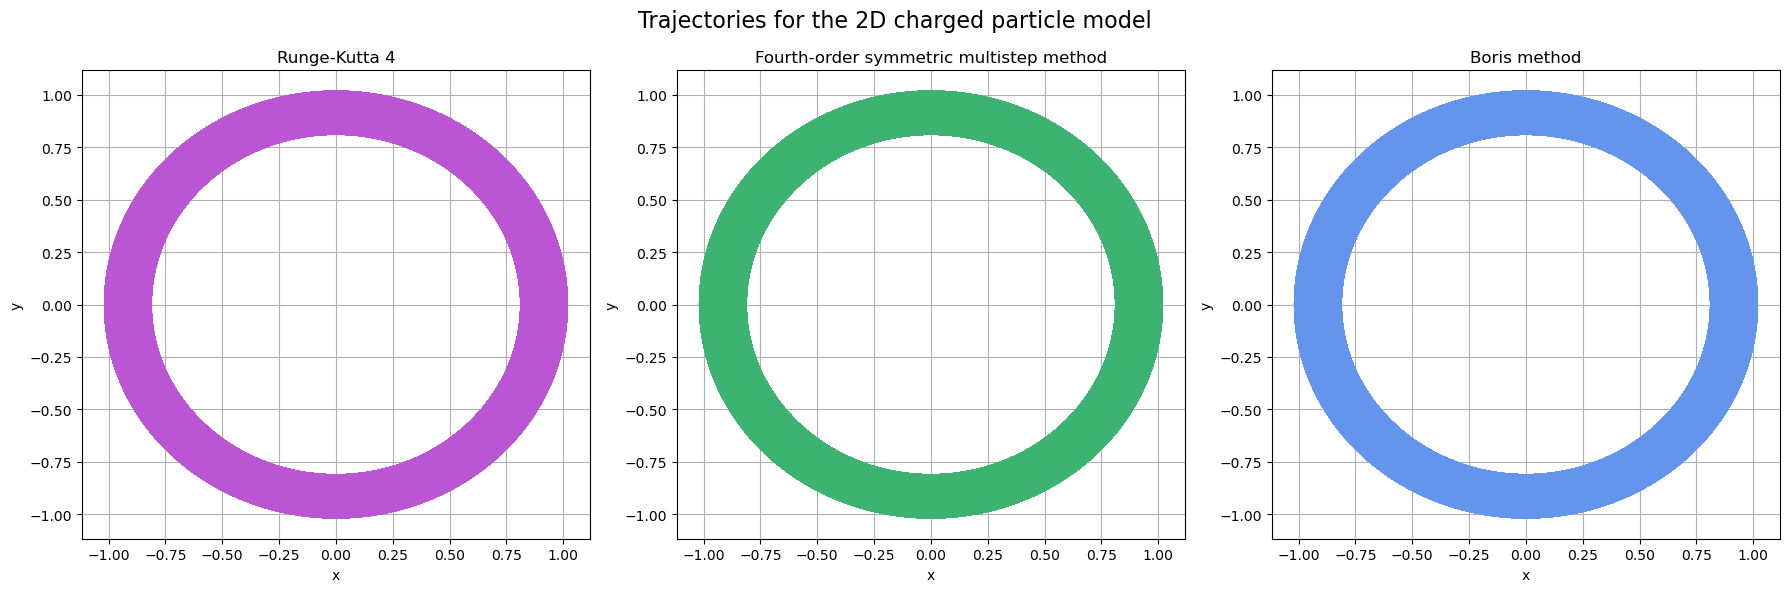

In [171]:
#Alle 2D-plott ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Figure 1: Trajectories for the 2D charged particle model", fontsize=16)

#RK4
axes[0].plot(x_RK4_2D[:, 0], x_RK4_2D[:, 1], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_2D[0, :], x_FOSMM_2D[1, :], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_2D[0], x_boris_2D[1], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

plt.tight_layout()
plt.show()

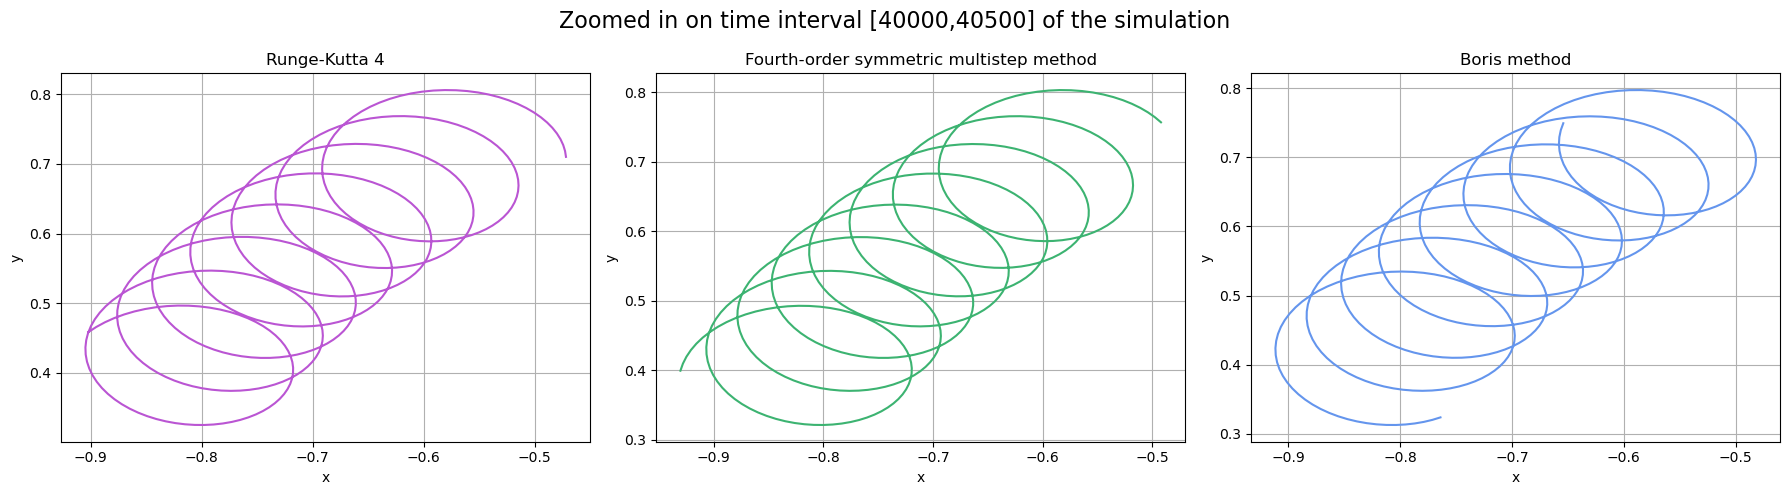

In [172]:
# ZOOMED-IN PLOTS OVER A SHORT TIME INTERVAL
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(x_RK4_2D[:, 0][40000:40500], x_RK4_2D[:, 1][40000:40500], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_2D[0, :][40000:40500], x_FOSMM_2D[1, :][40000:40500], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_2D[0][40000:40500], x_boris_2D[1][40000:40500], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

for ax in axes:
    ax.grid(True)

fig.suptitle("Figure 2: Zoomed in on time interval [40000,40500] of the simulation", fontsize=16)
plt.tight_layout()
plt.show()

we observe a "phase difference"

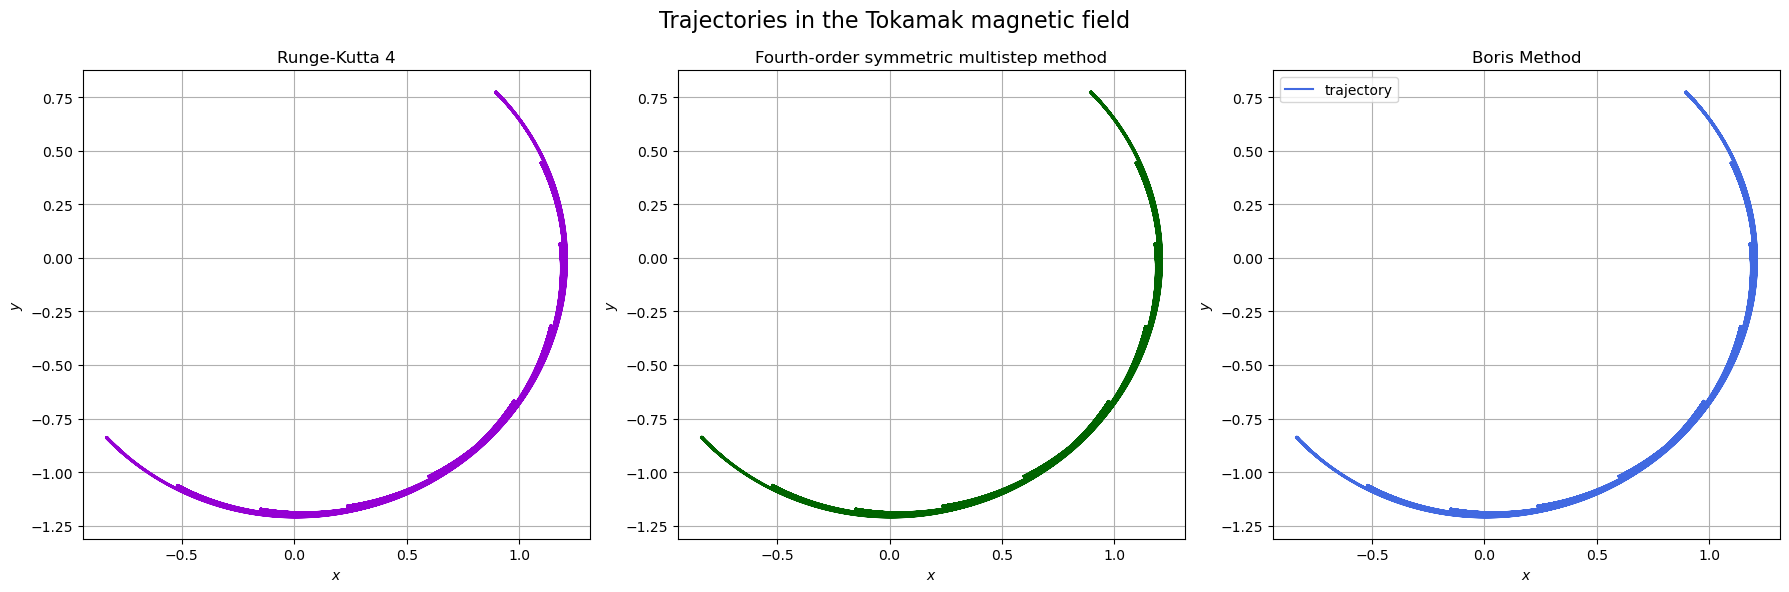

In [173]:
#Alle Tokamak-baner (x1-x2-planet) ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_RK4_tok[:, 0], x_RK4_tok[:, 1], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_tok[0, :], x_FOSMM_tok[1, :], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_tok[0], x_boris_tok[1], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Figure 3: Trajectories in the Tokamak magnetic field", fontsize=16)
plt.tight_layout()
plt.show()

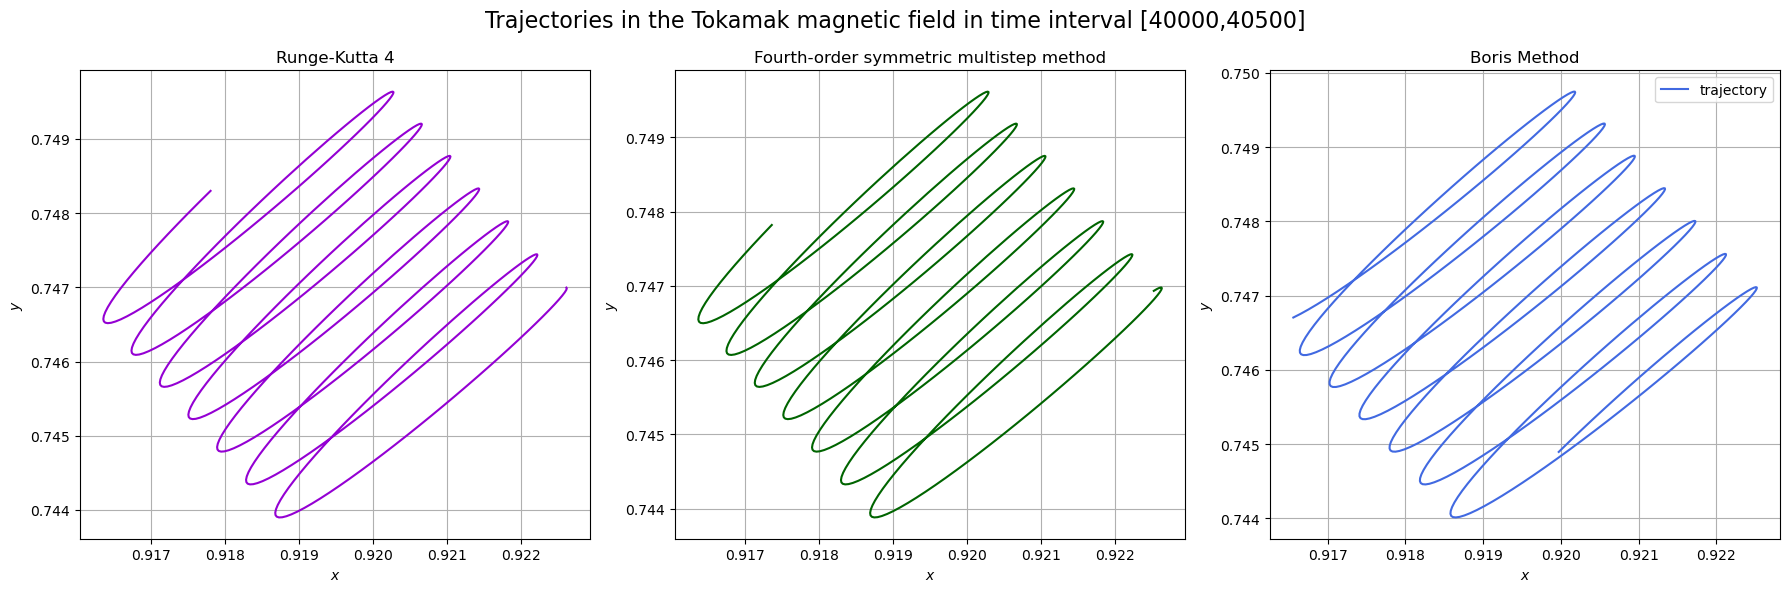

In [174]:
#Zoom in on smaller time interval
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_RK4_tok[:, 0][40000:40500], x_RK4_tok[:, 1][40000:40500], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_tok[0, :][40000:40500], x_FOSMM_tok[1, :][40000:40500], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_tok[0][40000:40500], x_boris_tok[1][40000:40500], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Figure 4: Trajectories in the Tokamak magnetic field in time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()

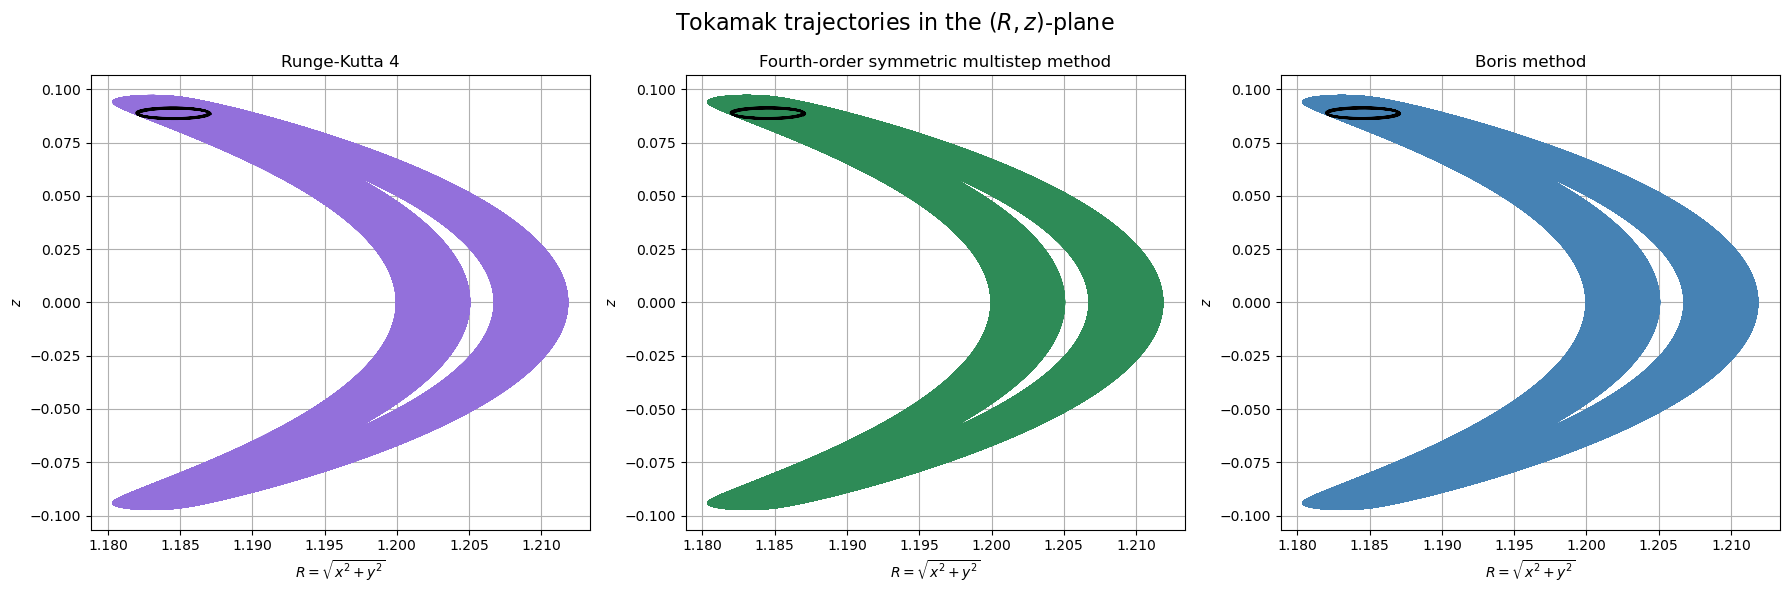

In [175]:
#Alle Tokamak-baner i R-x3-planet ved siden av hverandre
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R_RK4_tok, z_RK4_tok, color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2), x_FOSMM_tok[2, :], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok, z_boris_tok, color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


axes[0].plot(R_RK4_tok[40000:40500], z_RK4_tok[40000:40500], color="black")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2)[40000:40500], x_FOSMM_tok[2, :][40000:40500], color="black")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok[40000:40500], z_boris_tok[40000:40500], color="black")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Figure 5: Tokamak trajectories in the $(R, z)$-plane", fontsize=16)
plt.tight_layout()
plt.show()

we zoom in on the black part:

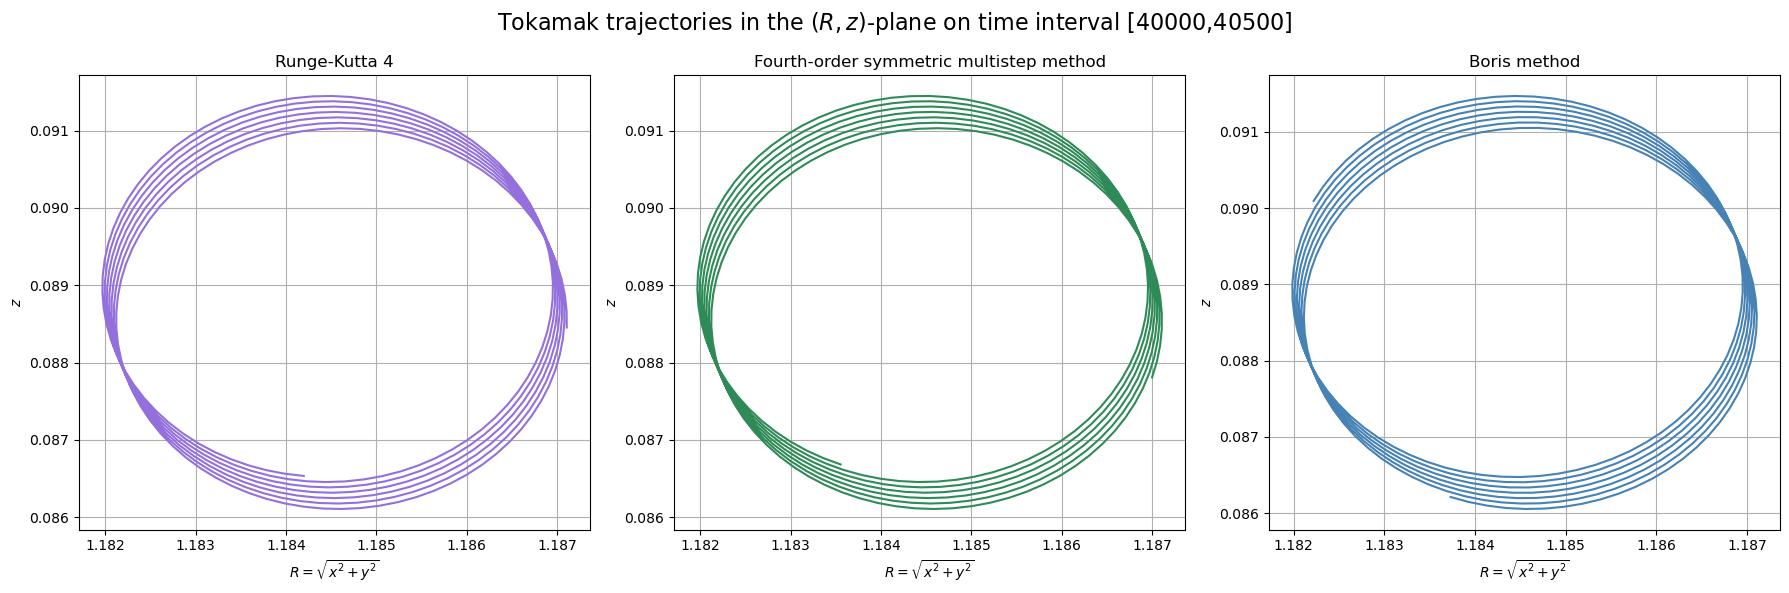

In [176]:
#Zooomed in interval
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R_RK4_tok[40000:40500], z_RK4_tok[40000:40500], color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2)[40000:40500], x_FOSMM_tok[2, :][40000:40500], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok[40000:40500], z_boris_tok[40000:40500], color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Figure 6: Tokamak trajectories in the $(R, z)$-plane on time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()

# 5. Task A: Referanseløsninger og feil over tid

## Reference solutions for task A (one per model, used by all three methods)

In [ ]:
# One reference solution per model on the grid t_A. Used by Boris, RK4 and FOSMM
sol_A_2D = solve_ivp(ODEs, (0, T_A), y0_2D,
                     args=(B_2D, grad_U_2D),
                     method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_A)

sol_A_tok = solve_ivp(ODEs, (0, T_A), y0_tok,
                      args=(B_tokamak, grad_U_tokamak),
                      method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_A)

print(sol_A_2D.success, sol_A_2D.message)
print(sol_A_tok.success, sol_A_tok.message)

1000000


## Error for Boris

In [179]:
# Boris stores x at t_1, ..., t_N, so it is compared with the reference from t_1
err_boris_2D = np.linalg.norm(x_boris_2D - sol_A_2D.y[:3, 1:], axis = 0, ord = 2)

In [180]:
err_boris_tok = np.linalg.norm(x_boris_tok - sol_A_tok.y[:3, 1:], axis = 0, ord = 2)

## Error for RK4

In [182]:
# Transposing to make the shapes match: x_RK4 has shape (N+1, 3), sol.y[:3] has shape (3, N+1)
err_RK4_2D = np.linalg.norm(x_RK4_2D - sol_A_2D.y[:3, :].T, axis = 1)

err_RK4_tok = np.linalg.norm(x_RK4_tok - sol_A_tok.y[:3, :].T, axis = 1)

## Error for FOSMM

In [184]:
def error(x, xref):
    return np.linalg.norm(x-xref, ord=2, axis = 0)

err_FOSMM_2D = error(x_FOSMM_2D, sol_A_2D.y[:3])
err_FOSMM_tok = error(x_FOSMM_tok, sol_A_tok.y[:3])

/opt/homebrew/Caskroom/miniconda/base/envs/project/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


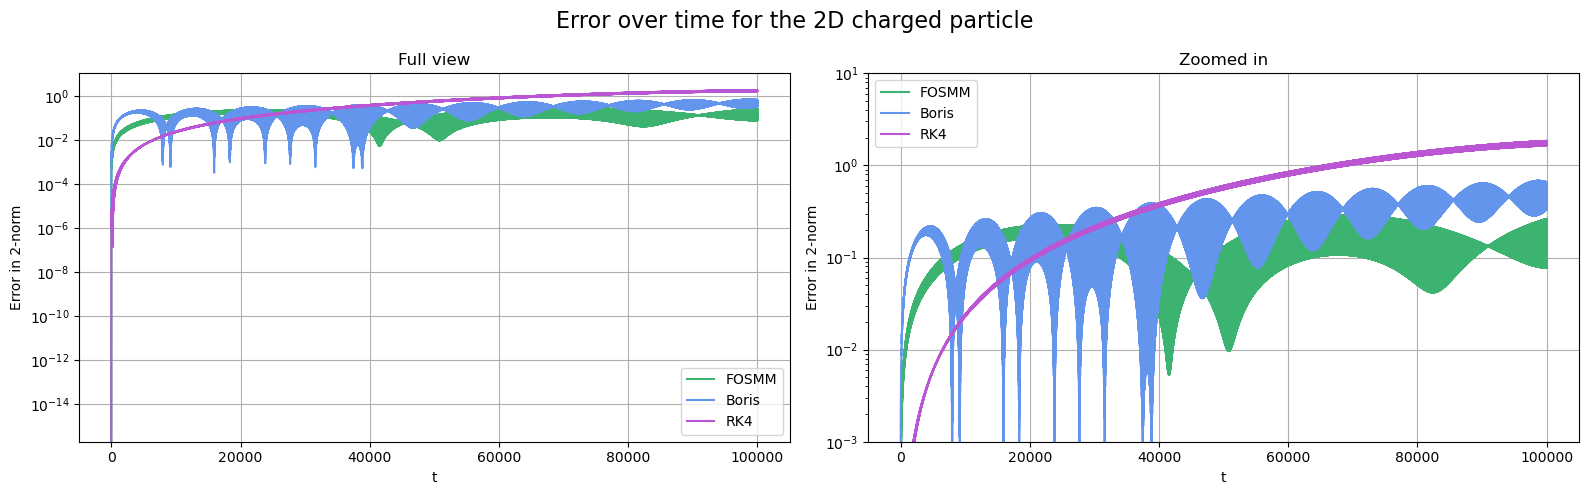

In [185]:
# ERROR FOR 2D-PARTICLE IN DIFFERENT MODELS:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(np.linspace(0, T_A, len(err_FOSMM_2D)), err_FOSMM_2D, color='mediumseagreen', label='FOSMM')
    ax.semilogy(t_A_boris, err_boris_2D, color='cornflowerblue', label='Boris')
    ax.semilogy(t_A, err_RK4_2D, color='mediumorchid', label='RK4')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-3, 1e1)

fig.suptitle('Figure 7: Error over time for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()

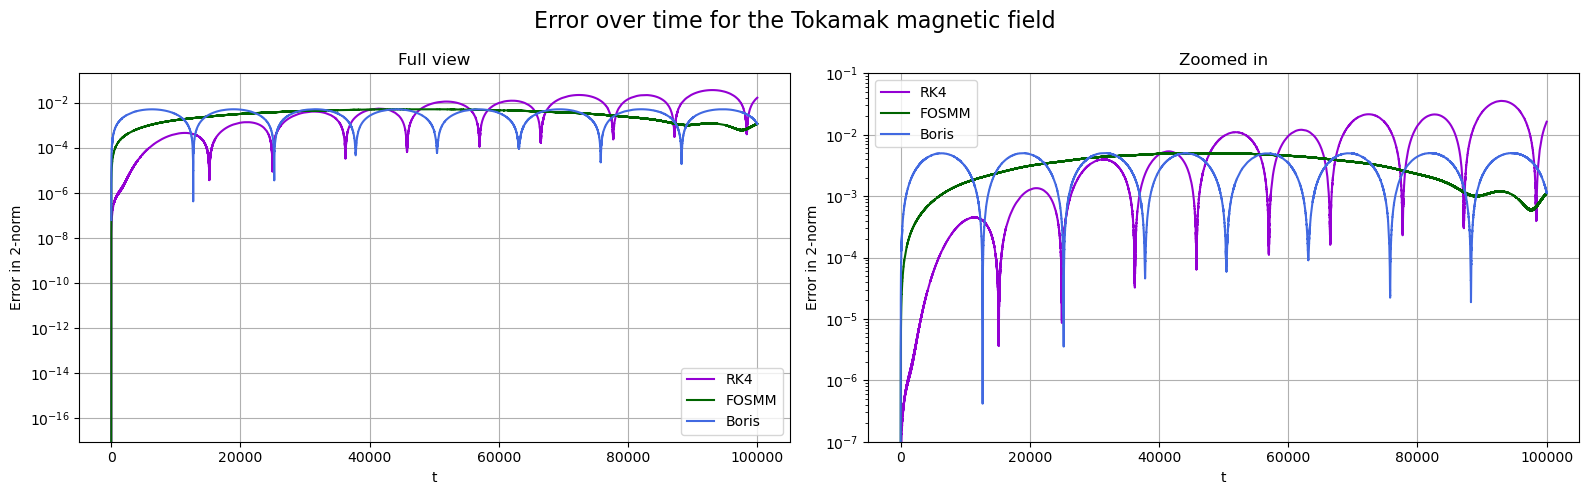

In [186]:
# ERROR OVER TIME FOR TOKAMAK FIELD WITH DIFFERENT METHODS:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(t_A, err_RK4_tok, color='darkviolet', label='RK4')
    ax.semilogy(np.linspace(0, T_A, len(err_FOSMM_tok)), err_FOSMM_tok, color='darkgreen', label='FOSMM')
    ax.semilogy(t_A_boris, err_boris_tok, color='royalblue', label='Boris')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-7, 1e-1)   # juster grensene etter hvordan plottet ser ut

fig.suptitle('Figure 8: Error over time for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()

# 6. Task A: Energi

## Boris

In [187]:
def energy_change_boris(x,v, initial_values, U):

    v_at_integers = 0.5* (v[:,:-1] + v[:, 1:])


    energy_at_zero = energy(initial_values[0:3], initial_values[3:], U)

    x_array = x[:, :-1]

    energy_at_x_v = energy(x_array, v_at_integers, U)

    diff = np.abs(energy_at_x_v - energy_at_zero)

    return diff

dE_boris_2D = energy_change_boris(x_boris_2D, v_boris_2D, y0_2D, U_2D)
dE_boris_tok = energy_change_boris(x_boris_tok, v_boris_tok, y0_tok, U_tokamak)

t_eval_boris = t_A_boris[:-1]   # times t_1, ..., t_{N-1}, where v can be averaged to whole steps

## RK4

---------------------------------------------------------------

In [188]:
#Change in energy for RK4
E0_2D = energy(y0_2D[:3], y0_2D[3:], U_2D)
E0_tok = energy(y0_tok[:3], y0_tok[3:], U_tokamak)

dE_RK4_2D = np.abs(energy(x_RK4_2D.T, v_RK4_2D.T, U_2D) - E0_2D)
dE_RK4_tok = np.abs(energy(x_RK4_tok.T, v_RK4_tok.T, U_tokamak) - E0_tok)

## FOSMM

compare to theorem: h^-7 = 10^7 so should hold for the entire time interval, which it does, as we can see both errors are below the O(h^4) limit.

compare results 

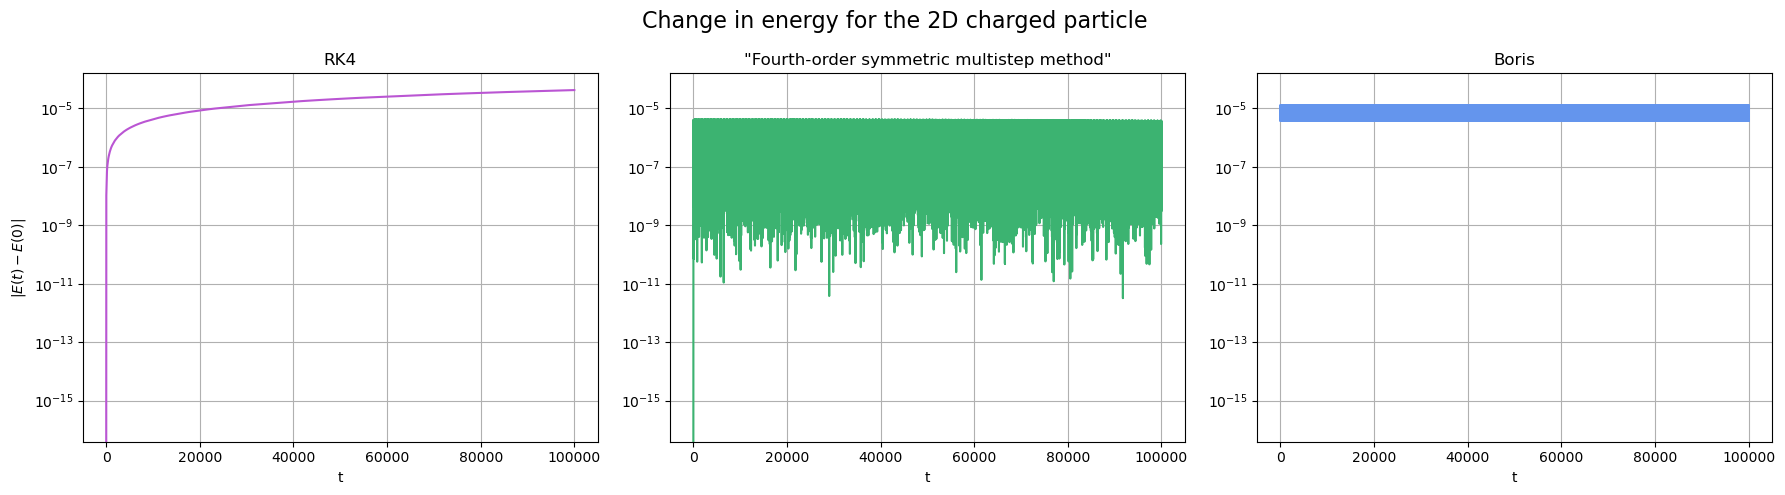

In [189]:
# ENERGY CHANGE FOR THE 2D PARTICLE, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)


#RK4
axes[0].semilogy(t_A, dE_RK4_2D, color='mediumorchid')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_A, energy_change(x_FOSMM_2D, v_FOSMM_2D, U_2D), color='mediumseagreen')
axes[1].set_title('"Fourth-order symmetric multistep method"')

#Boris
axes[2].semilogy(t_eval_boris, dE_boris_2D, color='cornflowerblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Figure 9: Change in energy for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()

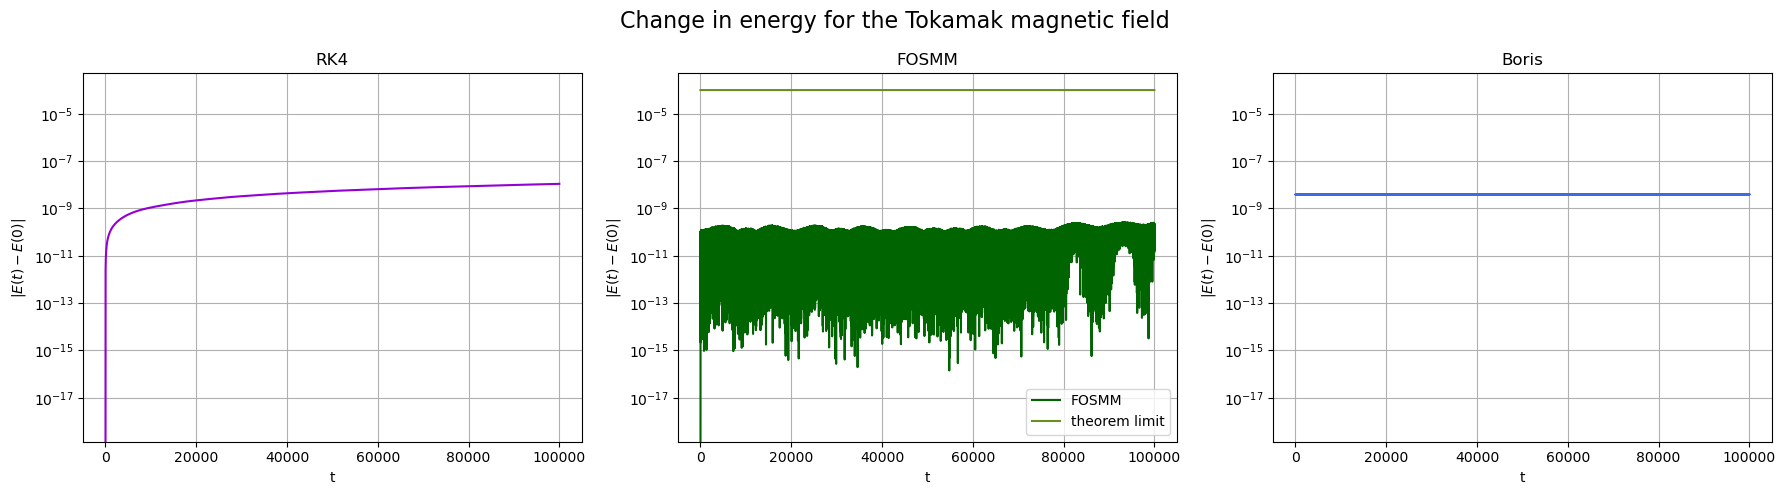

In [190]:
# ENERGY CHANGE FOR THE TOKAMAK FIELD, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

#RK4
axes[0].semilogy(t_A, dE_RK4_tok, color='darkviolet')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_A, energy_change(x_FOSMM_tok, v_FOSMM_tok, U_tokamak), color='darkgreen', label='FOSMM')
axes[1].semilogy(t_A, h_A**4*np.ones(len(t_A)), color='olivedrab', label='theorem limit')
axes[1].set_title('FOSMM')
axes[1].legend()

#Boris
axes[2].semilogy(t_eval_boris, dE_boris_tok, color='royalblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
    ax.set_ylabel(r'$|E(t) - E(0)|$')
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Figure 10: Change in energy for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()

SAMMENLIKN ALLE RESULTATER MED FORVENTNINGER! se oppgaveteksten


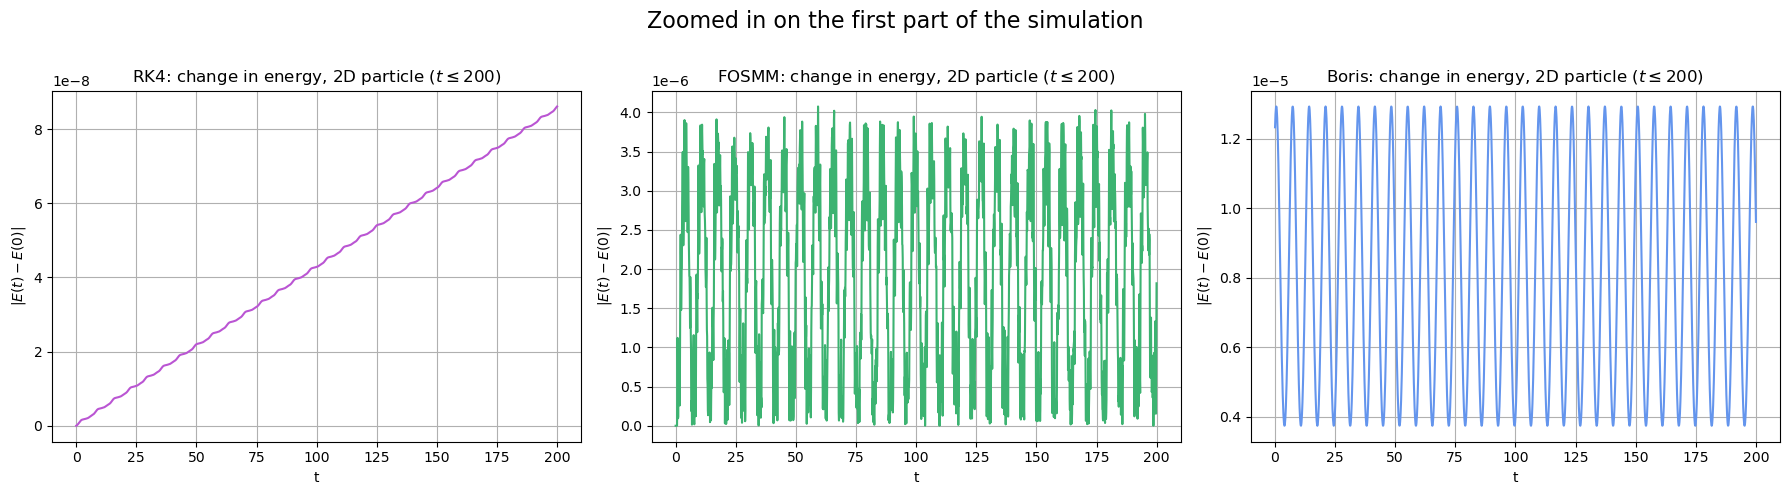

In [191]:
# ZOOMED-IN PLOTS OVER A SHORT TIME INTERVAL
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4: energy change

axes[0].plot(t_A[:2000], dE_RK4_2D[:2000], color="mediumorchid")
axes[0].set_title("RK4: change in energy, 2D particle ($t \\leq 200$)")
axes[0].set_xlabel("t")
axes[0].set_ylabel(r"$|E(t) - E(0)|$")

#FOSMM: energy change
axes[1].plot(t_A[:2000], energy_change(x_FOSMM_2D[:,:200*10], v_FOSMM_2D[:,:200*10], U_2D), color="mediumseagreen")
axes[1].set_title("FOSMM: change in energy, 2D particle ($t \\leq 200$)")
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"$|E(t) - E(0)|$")

#Boris: energy change
axes[2].plot(t_A_boris[:2000], dE_boris_2D[:2000], color="cornflowerblue")
axes[2].set_title("Boris: change in energy, 2D particle ($t \\leq 200$)")
axes[2].set_xlabel("t")
axes[2].set_ylabel(r"$|E(t) - E(0)|$")

for ax in axes:
    ax.grid(True)

fig.suptitle("Figure 11: Zoomed in on the first part of the simulation", fontsize=16)
plt.tight_layout()
plt.show()

# 7. Task B: Konvergens og work-precision

#### Parameters for task B (shared by all methods)

In [ ]:
# Final times and step sizes for task B, shared by Boris, RK4 and FOSMM
T_B = [1e4, 1e3, 1e2, 10]
h_B = 0.1/2**np.arange(3)      # [0.1, 0.05, 0.025]

## Boris

In [192]:
def error_boris_decrease(T):
    errors_2d = []
    errors_tok = []
    time_list_2d = []
    time_list_tok = []

    for h in h_B:
        N = int(T/h)   # same number of steps as RK4 and FOSMM, ends at T

        t_span = (0, T)
        t_eval = np.arange(1, N+1) * h   # x_array[:, k] from boris_method is the position at t = (k+1)h

        x_boris_2D_h, _, time_2d = boris_method(ODEs, x0_2D, v0_2D, h, U_2D, grad_U_2D, B_2D, True, N)

        sol_2D = solve_ivp(ODEs, t_span, y0_2D,
                args=(B_2D, grad_U_2D),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        x_boris_tok_h, _, time_tok = boris_method(ODEs, x0_tokamak, v0_tokamak, h, U_tokamak, grad_U_tokamak, B_tokamak, True, N)

        time_list_2d.append(time_2d)
        time_list_tok.append(time_tok)

        sol_tok = solve_ivp(ODEs, t_span, y0_tok,
                args=(B_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        # Compare last step global error
        norm_2D = np.linalg.norm(x_boris_2D_h[:,-1] - sol_2D.y[:3,-1], ord = 2)
        norm_tok = np.linalg.norm(x_boris_tok_h[:,-1] - sol_tok.y[:3,-1], ord = 2)

        errors_2d.append(norm_2D)
        errors_tok.append(norm_tok)

    return errors_2d, errors_tok, time_list_2d, time_list_tok

In [193]:
# Errors and times for each final time in T_B (index k corresponds to T_B[k])
results_boris = [error_boris_decrease(T) for T in T_B]

err_boris_2D_B   = [r[0] for r in results_boris]
err_boris_tok_B  = [r[1] for r in results_boris]
time_boris_2D_B  = [r[2] for r in results_boris]
time_boris_tok_B = [r[3] for r in results_boris]

## RK4

## Task B) Order verification and work precision diagrams

In [122]:
def error_RK4_decrease(T):

    N_h = (T / h_B).astype(int)

    # Reference solutions at final time T
    sol_2D = solve_ivp(
        ODEs, (0, T), y0_2D,
        args=(B_2D, grad_U_2D),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T]
    )

    sol_tokamak = solve_ivp(
        ODEs, (0, T), y0_tok,
        args=(B_tokamak, grad_U_tokamak),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T]
    )

    # Lists for errors and computation times
    error_2D = []
    error_tokamak = []
    time_2D = []
    time_tokamak = []

    # RK4 for each step size: 2D and Tokamak
    for i in range(3):

        # 2D
        y_n = y0_2D.copy()

        start = perf_counter()

        for j in range(N_h[i]):
            y_n = RK4_step(y_n, h_B[i], B_2D, grad_U_2D)

        end = perf_counter()
        time_2D.append(end - start)

        error_2D.append(np.linalg.norm(y_n[:3] - sol_2D.y[:3, -1]))

        # Tokamak
        y_n = y0_tok.copy()

        start = perf_counter()

        for j in range(N_h[i]):
            y_n = RK4_step(y_n, h_B[i], B_tokamak, grad_U_tokamak)

        end = perf_counter()
        time_tokamak.append(end - start)

        error_tokamak.append(np.linalg.norm(y_n[:3] - sol_tokamak.y[:3, -1]))

    return error_2D, error_tokamak, time_2D, time_tokamak

In [144]:
# Errors and times for each final time in T_B (index k corresponds to T_B[k])
results_RK4 = [error_RK4_decrease(T) for T in T_B]

err_RK4_2D_B   = [r[0] for r in results_RK4]
err_RK4_tok_B  = [r[1] for r in results_RK4]
time_RK4_2D_B  = [r[2] for r in results_RK4]
time_RK4_tok_B = [r[3] for r in results_RK4]

## FOSMM

Task B) FOSMM

In [199]:
# 2D particle and Tokamak field, for each final time T in T_B and each step size h in h_B
# (index k corresponds to T_B[k], and each entry is a list over h_B)
err_FOSMM_2D_B, err_FOSMM_tok_B, time_FOSMM_2D_B, time_FOSMM_tok_B = [], [], [], []

for T in T_B:
    e_2D, e_tok, t_2D, t_tok = [], [], [], []
    for h in h_B:
        N = int(T/h) + 1
        t_eval = np.linspace(0, T, N)
        x_2D, _, time_2D = FOSMM(alpha, h, A_2D, grad_U_2D, B_2D, beta, T, y0_FOSMM_2D)
        x_tok, _, time_tok = FOSMM(alpha, h, A_tokamak, grad_U_tokamak, B_tokamak, beta, T, y0_FOSMM_tok)

        ref_2D = solve_ivp(ODEs, (0, T), y0_2D, args=(B_2D, grad_U_2D), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)
        ref_tok = solve_ivp(ODEs, (0, T), y0_tok, args=(B_tokamak, grad_U_tokamak), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        t_2D.append(time_2D)
        t_tok.append(time_tok)

        e_2D.append(np.linalg.norm(x_2D[:,-1] - ref_2D.y[:3,-1], ord=2))
        e_tok.append(np.linalg.norm(x_tok[:,-1] - ref_tok.y[:3,-1], ord=2))

    err_FOSMM_2D_B.append(e_2D)
    err_FOSMM_tok_B.append(e_tok)
    time_FOSMM_2D_B.append(t_2D)
    time_FOSMM_tok_B.append(t_tok)

In [ ]:
# GLOBAL ERROR VS STEP SIZE, T = 1e4, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[0], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[0], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[0], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[0], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[0], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[0], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 12: Global error versus step size using T = 1e4', fontsize=16)
plt.tight_layout()
plt.show()

perhaps also weird for boris due to phase?

In [ ]:
# GLOBAL ERROR VS STEP SIZE, T = 1e3, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[1], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[1], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[1], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[1], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[1], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[1], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 13: Global error versus step size using T = 1e3', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# GLOBAL ERROR VS STEP SIZE, T = 1e2, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[2], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[2], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[2], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[2], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[2], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[2], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 14: Global error versus step size using T = 1e2', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# GLOBAL ERROR VS STEP SIZE, T = 10, ONE SUBPLOT PER METHOD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[3], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[3], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[3], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[3], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[3], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[3], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 15: Global error versus step size using T = 10', fontsize=16)
plt.tight_layout()
plt.show()

as we can see, the errors grow asymptotically as h**4

VISE MER ORDENTLIG???

fra øving 2: Compute Rn,0 for n= 0,1,2 (composite trapezoidal rule with 1, 2, and 4
subintervals). Verify that the errors are approximately in the ratio 4 : 1
when the step size is halved, consistent with O(h2) convergence.
DETTE MÅ FORKLARES
OI NEI MEN i følge argumentasjonen for RK4 så er jo da denne ikke orden 4??? For h < h0 vil de være større enn O(h^4)?

which method most efficient for a given tolerrance?

makes sense, more time = more accurcay and vice versa

since the plots of the error have a steeper slope than the h**4 plot, for some h0 >0 we will have that the errors are below Ch^4 for all h <= h0, thus the O(h^4) condition for convergence of order p is satisfied. 

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e4
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[0], time_RK4_2D_B[0], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[0], time_FOSMM_2D_B[0], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[0], time_boris_2D_B[0], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 16: Work-precision diagram for the 2D charged particle, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e4
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[0], time_RK4_tok_B[0], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[0], time_FOSMM_tok_B[0], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[0], time_boris_tok_B[0], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 17: Work-precision diagram for the Tokamak magnetic field, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e3
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[1], time_RK4_2D_B[1], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[1], time_FOSMM_2D_B[1], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[1], time_boris_2D_B[1], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 18: Work-precision diagram for the 2D charged particle, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e3
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[1], time_RK4_tok_B[1], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[1], time_FOSMM_tok_B[1], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[1], time_boris_tok_B[1], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 19: Work-precision diagram for the Tokamak magnetic field, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 1e2
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[2], time_RK4_2D_B[2], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[2], time_FOSMM_2D_B[2], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[2], time_boris_2D_B[2], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 20: Work-precision diagram for the 2D charged particle, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 1e2
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[2], time_RK4_tok_B[2], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[2], time_FOSMM_tok_B[2], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[2], time_boris_tok_B[2], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 21: Work-precision diagram for the Tokamak magnetic field, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE 2D PARTICLE, ALL METHODS, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[3], time_RK4_2D_B[3], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[3], time_FOSMM_2D_B[3], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[3], time_boris_2D_B[3], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 22: Work-precision diagram for the 2D charged particle, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# WORK-PRECISION DIAGRAM FOR THE TOKAMAK FIELD, ALL METHODS, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[3], time_RK4_tok_B[3], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[3], time_FOSMM_tok_B[3], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[3], time_boris_tok_B[3], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 23: Work-precision diagram for the Tokamak magnetic field, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

-----------------------------

# Task C

## Task C RK4 method

In [225]:
# Parameters
T_C = 2e5
h_C = np.pi/10
n_steps_C = int(T_C/h_C)
time_C = np.linspace(0, T_C, n_steps_C + 1)

# Preallocating array
y_arr_tokamak_RK4_C_banana = np.zeros((n_steps_C + 1, 6))
y_arr_tokamak_RK4_C_transit = np.zeros((n_steps_C + 1, 6))

x0_tokamak_C = np.array([1.05,0,0])
v0_tokamak_C_banana = np.array([0,4.816e-4,-2.059e-3]) #for banana orbit
v0_tokamak_C_transit = np.array([0,2*4.816e-4,-2.059e-3]) #for transit orbit

# Initial condition: position + velocity
y_arr_tokamak_RK4_C_banana[0] = np.concatenate((
    np.asarray(x0_tokamak_C), np.asarray(v0_tokamak_C_banana)))
y_arr_tokamak_RK4_C_transit[0] = np.concatenate((
    np.asarray(x0_tokamak_C), np.asarray(v0_tokamak_C_transit)))


#FORTSETT EHR
y_n_RK4_banana = np.concatenate((x0_tokamak_C, v0_tokamak_C_banana))
y_n_RK4_transit = np.concatenate((x0_tokamak_C, v0_tokamak_C_transit))


for i in tqdm(range(n_steps_C)):
    y_n_RK4_banana = RK4_step(y_n_RK4_banana, h_C, B_tokamak, grad_U_tokamak)
    y_n_RK4_transit = RK4_step(y_n_RK4_transit, h_C, B_tokamak, grad_U_tokamak)

    y_arr_tokamak_RK4_C_banana[i+1] = np.asarray(y_n_RK4_banana)
    y_arr_tokamak_RK4_C_transit[i+1] = np.asarray(y_n_RK4_transit)

# Extracting position and velocity
x_arr_tokamak_RK4_C_banana = y_arr_tokamak_RK4_C_banana[:, :3]
v_arr_tokamak_RK4_C_banana = y_arr_tokamak_RK4_C_banana[:, 3:]

x_arr_tokamak_RK4_C_transit = y_arr_tokamak_RK4_C_transit[:, :3]
v_arr_tokamak_RK4_C_transit = y_arr_tokamak_RK4_C_transit[:, 3:]

100%|██████████| 636619/636619 [01:48<00:00, 5888.52it/s]


In [226]:
#Plotting the trajectories of the two first coordinates of the solutions
# Cylindrical radial coordinate
R_RK4_C_banana = np.sqrt(x_arr_tokamak_RK4_C_banana[:, 0]**2 + x_arr_tokamak_RK4_C_banana[:, 1]**2)
R_RK4_C_transit = np.sqrt(x_arr_tokamak_RK4_C_transit[:, 0]**2 + x_arr_tokamak_RK4_C_transit[:, 1]**2)

x3_RK4_C_banana = x_arr_tokamak_RK4_C_banana[:, 2]
x3_RK4_C_transit = x_arr_tokamak_RK4_C_transit[:, 2]

In [227]:
# Calculate relative energy error (for banana orbit)
E_n_tokamak_RK4_C = energy(x_arr_tokamak_RK4_C_banana.T, v_arr_tokamak_RK4_C_banana.T, U_tokamak)
E0_tokamak_RK4_C = E_n_tokamak_RK4_C[0]


error_energy_tokamak = (E_n_tokamak_RK4_C - E0_tokamak_RK4_C) / np.abs(E0_tokamak_RK4_C)

## Task C Boris method

In [228]:
# Boris with initial conditions from article 3


x_c_boris_banana, v_c_boris_banana, _ = boris_method(ODEs, x0_tokamak_C, v0_tokamak_C_banana, h_C, U_tokamak, grad_U_tokamak, B_tokamak, True, n_steps_C)

x_c_boris_transit, v_c_boris_transit, _ = boris_method(ODEs, x0_tokamak_C, v0_tokamak_C_transit, h_C, U_tokamak, grad_U_tokamak, B_tokamak, True, n_steps_C)


In [229]:
t_span_c_boris = (0,T_C)
t_eval_c_boris = np.arange(1, n_steps_C + 1)*h_C   # boris_method stores x at t_1, ..., t_N

R_boris_C_banana = np.sqrt(x_c_boris_banana[0]**2 + x_c_boris_banana[1]**2)
R_boris_C_transit = np.sqrt(x_c_boris_transit[0]**2 + x_c_boris_transit[1]**2)

energy_tokamak_boris_C = energy(x_c_boris_banana,v_c_boris_banana,U_tokamak)

E0_tokamak_boris = energy_tokamak_boris_C[0]

error_energy_tokamak_boris = (energy_tokamak_boris_C - E0_tokamak_boris)/np.abs(E0_tokamak_boris)

## Task C: Sammenligning av RK4 og Boris

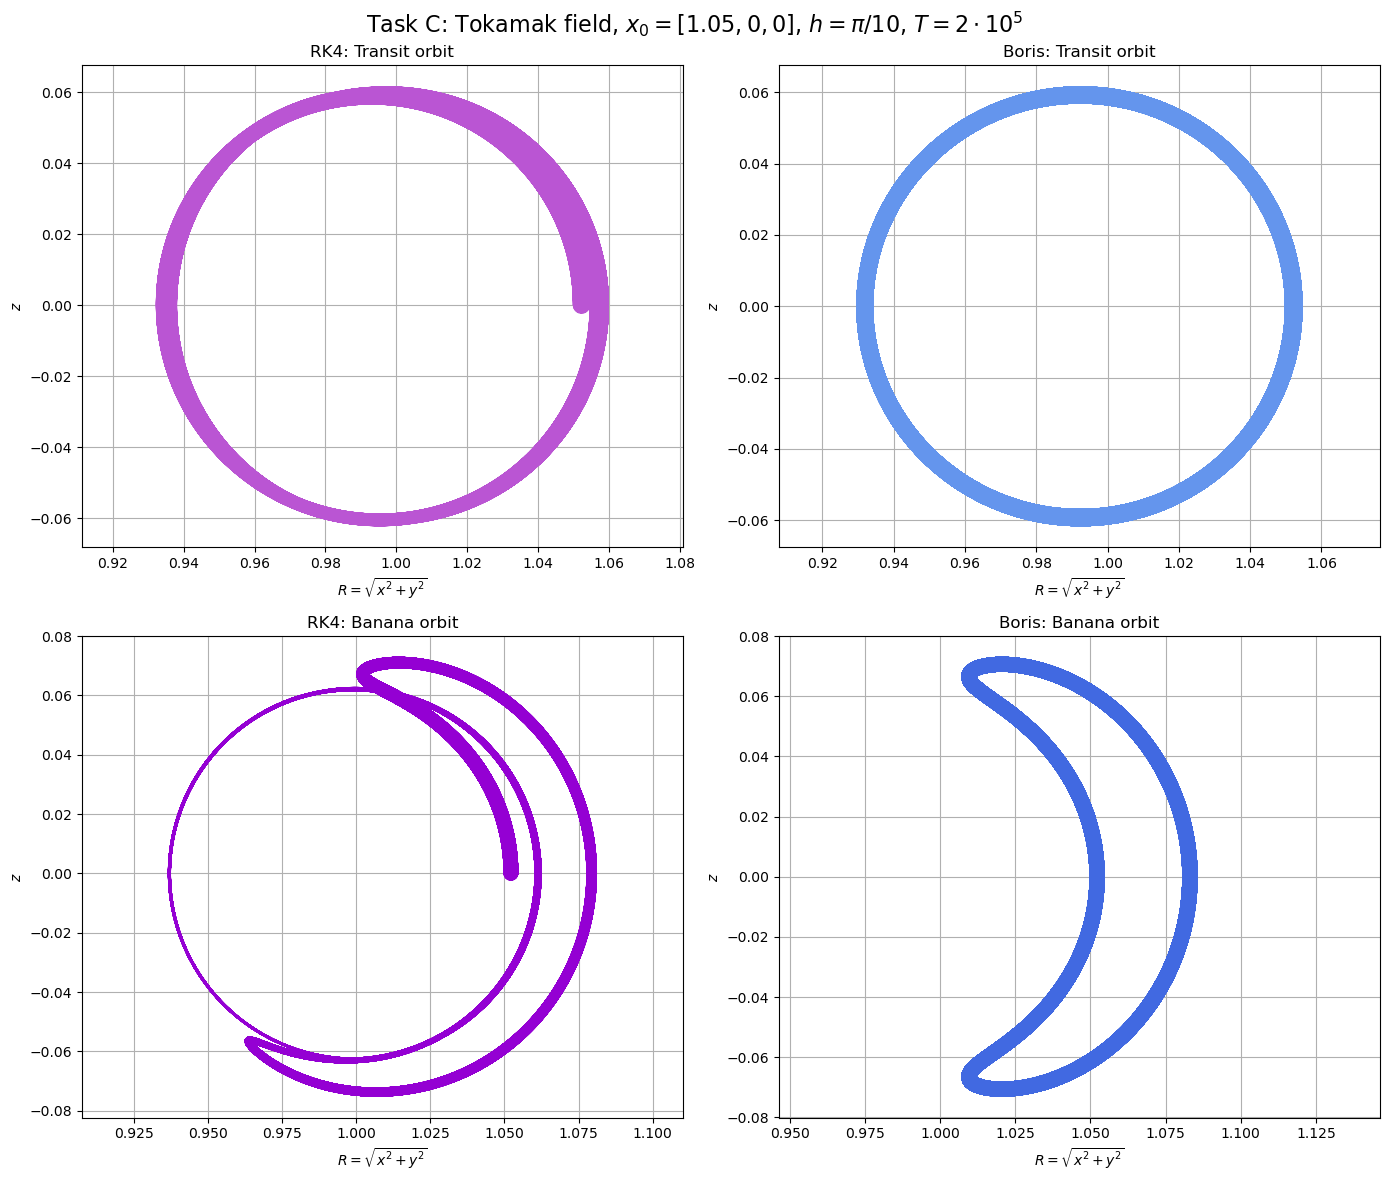

In [230]:
# TASK C: TRAJECTORIES FOR RK4 AND BORIS SIDE BY SIDE (cf. Fig. 6 in He et al. 2015)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

#RK4, (R,z)-plane, Transit orbit
axes[0, 0].plot(R_RK4_C_transit, x_arr_tokamak_RK4_C_transit[:, 2], color="mediumorchid")
axes[0, 0].set_title("RK4: Transit orbit")

#Boris, (R, z)-plane, Transit orbit
axes[0, 1].plot(R_boris_C_transit, x_c_boris_transit[2], color="cornflowerblue")
axes[0, 1].set_title("Boris: Transit orbit")

#RK4, (R, z)-plane, Banana orbit
axes[1, 0].plot(R_RK4_C_banana, x_arr_tokamak_RK4_C_banana[:, 2], color="darkviolet")
axes[1, 0].set_title("RK4: Banana orbit")

#Boris, (R, z)-plane, Banana orbit
axes[1, 1].plot(R_boris_C_banana, x_c_boris_banana[2], color="royalblue")
axes[1, 1].set_title("Boris: Banana orbit")


for ax in axes.flat:
    ax.set_xlabel(r"$R=\sqrt{x^2+y^2}$")
    ax.set_ylabel(r"$z$")
    ax.axis("equal")
    ax.grid(True)

fig.suptitle(r"Figure 24: Task C: Tokamak field, $x_0 = [1.05, 0, 0]$, $h = \pi/10$, $T = 2\cdot 10^5$", fontsize=16)
plt.tight_layout()
plt.show()


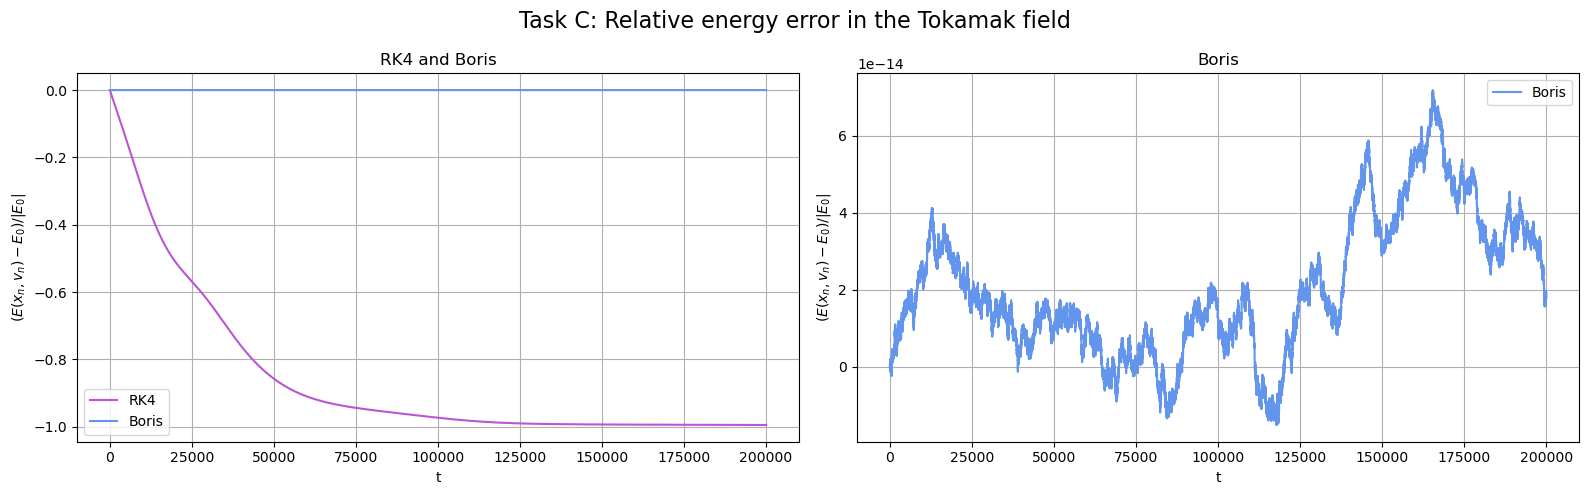

In [231]:
# TASK C: RELATIVE ENERGY ERROR FOR RK4 AND BORIS (cf. Fig. 7 in He et al. 2015)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#Both methods in the same plot
axes[0].plot(time_C, error_energy_tokamak, color="mediumorchid", label="RK4")
axes[0].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[0].set_title("RK4 and Boris")
axes[0].legend()

#Boris alone, so the size of the error is visible
axes[1].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[1].set_title("Boris")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel(r"$(E(x_n, v_n) - E_0)/|E_0|$")
    ax.grid(True)

fig.suptitle("Figure 25: Task C: Relative energy error in the Tokamak field", fontsize=16)
plt.tight_layout()
plt.show()


plotting momentum conservation for the original 2d model with T = 1e5:

In [ ]:
def M(x,v):
    A = np.array([A_2D(x[:, i]) for i in range(x.shape[1])]).T
    return (v[0,:] + A[0,:])*x[1,:] - (v[1,:] + A[1,:])*x[0,:]

v_at_integers_boris_2D = 0.5* (v_boris_2D[:,:-1] + v_boris_2D[:, 1:])
mom_RK4 = M(x_RK4_2D.T, v_RK4_2D.T)
mom_boris = M(x_boris_2D, v_at_integers_boris_2D)

mom_ref = M(sol_A_2D.y[:3, :], sol_A_2D.y[3:, :])

rel_error_mom_RK4 = (mom_RK4 - mom_ref)/np.abs(mom_ref)
rel_error_mom_boris = (mom_boris - mom_ref[1:-1])/np.abs(mom_ref[1:-1])

plt.title("Figure 26: Momentum conservation for our 2d model:")
plt.plot(t_A, rel_error_mom_RK4, label = "RK4")
plt.plot(t_A_boris, rel_error_mom_boris, label = "Boris")
plt.legend()
plt.xlabel('t')
plt.ylabel('Relative error')
plt.show()

#from paper 2